<a href="https://colab.research.google.com/github/pokovai/gyakorlas_git/blob/main/Feladatsor_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 5. feladatsor

**Név:** Pokovai Dénes, Szabados Benedek Imre, Szomjas Balázs Ede, Uri Kornél

**Feladat:** ISLP, 4.8. fejezet, 13. feladat (g, j) és 14. feladat (a-h)

A feladatsor központi témája a felügyelt osztályozás. Ilyenkor ismert kategóriájú megfigyelésekből építünk modellt, majd a modellt új adatok kategóriájának előrejelzésére használjuk.

Az első részben a `Weekly` adathalmazon azt vizsgáljuk, hogy korábbi hetek hozamaiból megjósolható-e a következő heti tőzsdei irány. Ehhez a K legközelebbi szomszéd, vagyis KNN-módszert használjuk. A második részben az `Auto` adathalmaz járműveit soroljuk alacsony és magas üzemanyag-hatékonyságú csoportba. Itt az LDA, QDA, logisztikus regresszió, naiv Bayes és KNN módszereket hasonlítjuk össze.


In [1]:
# Ha az ISLP csomag nincs telepitve, az alabbi sort egyszer kell futtatni:
%pip install ISLP

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ISLP import load_data
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis as QDA
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix

# Tevesztesi matrix letrehozasa
def confusion_table_hu(predicted, actual, labels):
    matrix = confusion_matrix(actual, predicted, labels=labels)
    return pd.DataFrame(
        matrix.T,
        index=pd.Index(labels, name="Predicted"),
        columns=pd.Index(labels, name="Truth")
    )

# Teszthiba kiszamitasa
def error_rate(actual, predicted):
    return np.mean(np.asarray(actual) != np.asarray(predicted))


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.6/16.6 MB 28.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 31.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 11.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 15.4 MB/s  0:00:00
  Created wheel for autograd-gamma: filename=autograd_gamma-0.5.0-py3-none-any.whl size=4118 sha256=7cae0b122507073755668d7e67dea7b53d0a52a1278e45d2bcad1e2340b4c9f7
  Stored in directory: /root/.cache/pip/wheels/7e/16/46/9477f188924292d3bf1fb8fb42844201591abfc19b7ba6d868
Successfully built autograd-gamma
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11/11 [ISLP]


# 13. feladat - Weekly adathalmaz

A `Weekly` adathalmaz 1990 és 2010 közötti heti tőzsdei adatokat tartalmaz. A `Direction` azt jelöli, hogy az adott héten a piac emelkedett vagy csökkent. A `Lag1` az előző hét, a `Lag2` a két héttel korábbi hét hozamát jelenti, és ugyanígy értelmezhetők a további változók is.

Az adathalmazt időrend szerint bontjuk fel. Az 1990-2008 közötti megfigyeléseken tanítjuk a modellt, a 2009-2010 közötti adatokat pedig tesztelésre tartjuk fenn. Az időrendi felosztás azért indokolt, mert egy valós előrejelzési helyzetben is múltbeli adatokból próbáljuk megbecsülni a jövőt. Így a teszteredmény közelebb áll a modell tényleges használatához.


In [2]:
# A Weekly adathalmaz betoltese es idobeli felosztasa
Weekly = load_data("Weekly")
weekly_train = Weekly[Weekly["Year"] <= 2008]
weekly_test = Weekly[Weekly["Year"] > 2008]

print("Training observations:", len(weekly_train))
print("Test observations:", len(weekly_test))


Training observations: 985
Test observations: 104


## 13. g) KNN-osztályozás K = 1 esetén

A KNN nem becsül hagyományos értelemben vett együtthatókat. Egy új tesztpont osztályát a hozzá legközelebb található tanítási megfigyelések alapján határozza meg. `K = 1` esetén kizárólag a legközelebbi megfigyelés kategóriája dönt.

Ebben a részben csak a `Lag2` változót használjuk. Ez azt jelenti, hogy két hét tőzsdei megfigyelése akkor számít hasonlónak, ha a két héttel korábbi hozamuk közel van egymáshoz. A módszer egyszerű, de `K = 1` esetén érzékeny lehet az egyedi, zajos megfigyelésekre, mivel egyetlen szomszéd határozza meg az eredményt.


In [3]:
# Tanitasi es tesztvaltozok letrehozasa
X_weekly_train = weekly_train[["Lag2"]]
X_weekly_test = weekly_test[["Lag2"]]
y_weekly_train = weekly_train["Direction"]
y_weekly_test = weekly_test["Direction"]

# KNN modell illesztese K = 1 ertekkel
knn_weekly_1 = KNeighborsClassifier(n_neighbors=1)
knn_weekly_1.fit(X_weekly_train, y_weekly_train)
weekly_predictions_1 = knn_weekly_1.predict(X_weekly_test)

# Tevesztesi matrix es talalati arany
weekly_confusion_1 = confusion_table_hu(
    weekly_predictions_1,
    y_weekly_test,
    ["Down", "Up"]
)
weekly_accuracy_1 = 1 - error_rate(y_weekly_test, weekly_predictions_1)

display(weekly_confusion_1)
print("Accuracy:", weekly_accuracy_1)


Truth,Down,Up
Predicted,,
Down,22,32
Up,21,29


Accuracy: 0.4903846153846154


A tévesztési mátrix alapján a modell 22 csökkenő és 29 emelkedő hetet osztályoz helyesen. Ugyanakkor 21 csökkenő hetet tévesen emelkedőnek, 32 emelkedő hetet pedig tévesen csökkenőnek jelez.

A 104 tesztmegfigyelésből 51-et sorol helyesen a modell, így a találati arány körülbelül **49,0%**. Ez még az 50%-os véletlen szintet sem éri el. A gyenge eredmény azt mutatja, hogy egyetlen közeli megfigyelés nem ad stabil döntést, valamint a `Lag2` önmagában gyenge információt tartalmaz a következő heti tőzsdei irányról.

Összefoglalva a `K = 1` modell túlságosan alkalmazkodik az egyedi tanítási pontokhoz. Emiatt a zajt is követi, és az új adatokon rosszul általánosít.


## 13. j) Különböző bemeneti változók és K értékek

A KNN egyik legfontosabb beállítása a `K`, vagyis a figyelembe vett szomszédok száma. Kis K értéknél a modell rugalmas, de érzékeny a zajra. Nagyobb K esetén több megfigyelés közös döntése alapján történik az osztályozás, ezért a modell stabilabb, viszont túl nagy K esetén a döntési határ túlságosan leegyszerűsödhet.

Először a `Lag2` változóval próbáljuk ki a `K = 1` és `K = 30` közötti értékeket. Ezután több változókombinációt is megvizsgálunk. Mivel a KNN távolságot számít, a változókat standardizáljuk. Standardizálás nélkül egy nagyobb számtartományú változó aránytalanul nagy hatással lehetne a távolságokra.

A skálázót kizárólag a tanítási adatokon illesztjük, majd ugyanazzal az átalakítással módosítjuk a tesztadatokat. Ez megakadályozza, hogy a tesztadatokból származó információ bekerüljön a tanítási folyamatba.


In [4]:
# Segedfuggveny egy valtozokombinacio es tobb K ertek vizsgalatahoz
def evaluate_knn_weekly(feature_names, k_values):
    X_train = weekly_train[feature_names]
    X_test = weekly_test[feature_names]

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    results = []
    for k in k_values:
        model = KNeighborsClassifier(n_neighbors=k)
        model.fit(X_train_scaled, y_weekly_train)
        predictions = model.predict(X_test_scaled)
        results.append({
            "variables": ", ".join(feature_names),
            "K": k,
            "accuracy": 1 - error_rate(y_weekly_test, predictions)
        })

    return pd.DataFrame(results)


In [5]:
# A Lag2 valtozo vizsgalata K = 1 es K = 30 kozott
weekly_lag2_results = evaluate_knn_weekly(["Lag2"], range(1, 31))

# A legjobb eredmenyek megjelenitese
weekly_lag2_results.sort_values(
    ["accuracy", "K"],
    ascending=[False, True]
).head(10)


,variables,K,accuracy
19,Lag2,20,0.596154
21,Lag2,22,0.596154
12,Lag2,13,0.586538
14,Lag2,15,0.586538
16,Lag2,17,0.586538
17,Lag2,18,0.586538
3,Lag2,4,0.576923
15,Lag2,16,0.576923
2,Lag2,3,0.567308
9,Lag2,10,0.567308


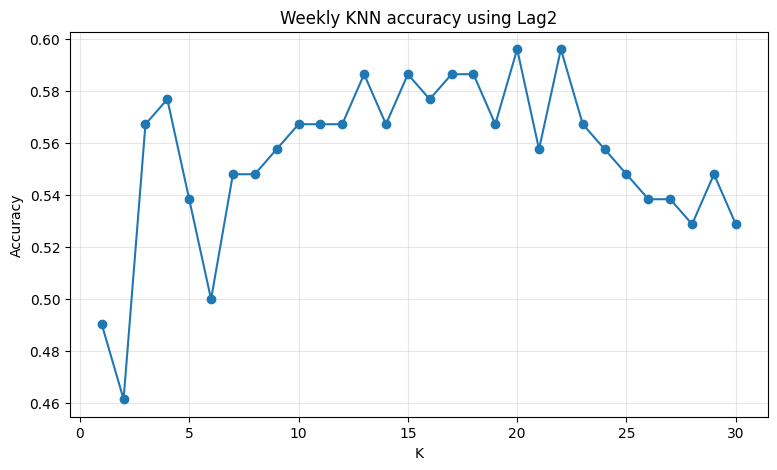

In [6]:
# A tesztpontossag abrazolasa K fuggvenyeben
plt.figure(figsize=(9, 5))
plt.plot(
    weekly_lag2_results["K"],
    weekly_lag2_results["accuracy"],
    marker="o"
)
plt.xlabel("K")
plt.ylabel("Accuracy")
plt.title("Weekly KNN accuracy using Lag2")
plt.grid(alpha=0.3)
plt.show()


A `Lag2` változóval a legjobb tesztpontosság körülbelül **59,6%**. Ezt több K érték, például 13, 17, 20 és 22 is elérheti. A nagyobb K érték tehát javít a `K = 1` modell 49%-os eredményén, mert a döntés már nem egyetlen zajos megfigyeléstől függ.

Az eredmény ugyanakkor továbbra sem tekinthető kiemelkedőnek. A körülbelül 60%-os pontosság csak mérsékelt előrejelző képességet jelent. Ez jól szemlélteti, hogy a pénzügyi idősorok következő irányának előrejelzése nehéz, és a késleltetett heti hozamokból csak korlátozott információ nyerhető ki.


In [7]:
# Tovabbi valtozokombinaciok vizsgalata
weekly_feature_sets = [
    ["Lag2"],
    ["Lag1", "Lag2"],
    ["Lag2", "Lag3", "Lag5"],
    ["Lag1", "Lag2", "Lag3", "Lag4", "Lag5"],
    ["Lag1", "Lag2", "Lag3", "Lag4", "Lag5", "Volume"]
]

weekly_all_results = pd.concat(
    [evaluate_knn_weekly(features, range(1, 31)) for features in weekly_feature_sets],
    ignore_index=True
)

# A valtozokombinaciok legjobb eredmenyei
weekly_best_by_features = (
    weekly_all_results
    .sort_values(["accuracy", "K"], ascending=[False, True])
    .groupby("variables", as_index=False)
    .first()
    .sort_values("accuracy", ascending=False)
)
weekly_best_by_features


,variables,K,accuracy
0,"Lag1, Lag2",25,0.625000
4,"Lag2, Lag3, Lag5",28,0.605769
3,Lag2,20,0.596154
2,"Lag1, Lag2, Lag3, Lag4, Lag5, Volume",23,0.576923
1,"Lag1, Lag2, Lag3, Lag4, Lag5",10,0.567308


Az eredmények alapján az összetettebb változókombinációk nem javítanak jelentősen az előrejelzésen. Több változó bevonása önmagában nem garantál jobb modellt. Ha az új változók kevés hasznos jelet és sok zajt tartalmaznak, akkor a távolságok kevésbé lesznek informatívak.

A `Weekly` adathalmaz esetében a `Lag2` önmagában is versenyképes a többváltozós KNN-modellekkel. Ez arra utal, hogy a többi késleltetett hozam és a forgalom nem ad elegendő új információt ahhoz, hogy a KNN teljesítménye lényegesen javuljon.


# 14. feladat - Auto adathalmaz

Az `Auto` adathalmaz különböző járművek műszaki jellemzőit és üzemanyag-hatékonyságát tartalmazza. Az `mpg` azt mutatja meg, hogy egy autó hány mérföldet képes megtenni egy gallon üzemanyaggal. Nagyobb `mpg` érték jobb üzemanyag-hatékonyságot jelent.

A feladatban nem a pontos `mpg` értéket becsüljük, hanem két csoportot hozunk létre: a medián alatti és a medián feletti fogyasztási kategóriát. Ezáltal a regressziós problémát bináris osztályozási problémává alakítjuk. Ezután több módszert ugyanazon tanítási és tesztfelosztáson hasonlítunk össze.


In [8]:
# Az Auto adathalmaz betoltese
Auto = load_data("Auto").dropna().copy()
Auto.head()


,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin
name,,,,,,,,
chevrolet chevelle malibu,18.0,8,307.0,130,3504,12.0,70,1
buick skylark 320,15.0,8,350.0,165,3693,11.5,70,1
plymouth satellite,18.0,8,318.0,150,3436,11.0,70,1
amc rebel sst,16.0,8,304.0,150,3433,12.0,70,1
ford torino,17.0,8,302.0,140,3449,10.5,70,1


## 14. a) Az `mpg01` bináris változó létrehozása

Az `mpg01` értéke 1, ha az autó `mpg` értéke nagyobb a minta mediánjánál, egyébként 0. A medián jelen esetben 22,75, tehát ez az érték választja ketté az adatokat alacsony és magas üzemanyag-hatékonyságú csoportra.

A medián használata azért előnyös, mert közel azonos méretű osztályokat eredményez, és kevésbé érzékeny a szélsőséges értékekre, mint az átlag. Fontos, hogy az eredeti `mpg` változót később nem használjuk bemeneti változóként, mert az `mpg01` közvetlenül ebből készült. Ha az `mpg` bekerülne a modellbe, az adatszivárgást okozna, és mesterségesen túl jó eredményt kapnánk.


In [9]:
# Az mpg medianjanak meghatarozasa
mpg_median = Auto["mpg"].median()

# A binaris mpg01 valtozo letrehozasa
Auto["mpg01"] = (Auto["mpg"] > mpg_median).astype(int)

print("MPG median:", mpg_median)
Auto.head()


MPG median: 22.75


,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin,mpg01
name,,,,,,,,,
chevrolet chevelle malibu,18.0,8,307.0,130,3504,12.0,70,1,0
buick skylark 320,15.0,8,350.0,165,3693,11.5,70,1,0
plymouth satellite,18.0,8,318.0,150,3436,11.0,70,1,0
amc rebel sst,16.0,8,304.0,150,3433,12.0,70,1,0
ford torino,17.0,8,302.0,140,3449,10.5,70,1,0


## 14. b) Grafikus adatvizsgálat

A modellezés előtt grafikusan megvizsgáljuk, mely változók különítik el legjobban a két `mpg01` kategóriát. A korrelációs hőtérkép a lineáris kapcsolatok irányát és erősségét mutatja, a pontdiagramok a csoportok elhelyezkedését, a dobozdiagramok pedig az eloszlások közötti különbségeket teszik láthatóvá.

A grafikus vizsgálat célja nem csupán az ábrák elkészítése. Ezek alapján választjuk ki a modellek bemeneti változóit, és előzetesen megfigyelhetjük, hogy várható-e jó osztályozási teljesítmény.


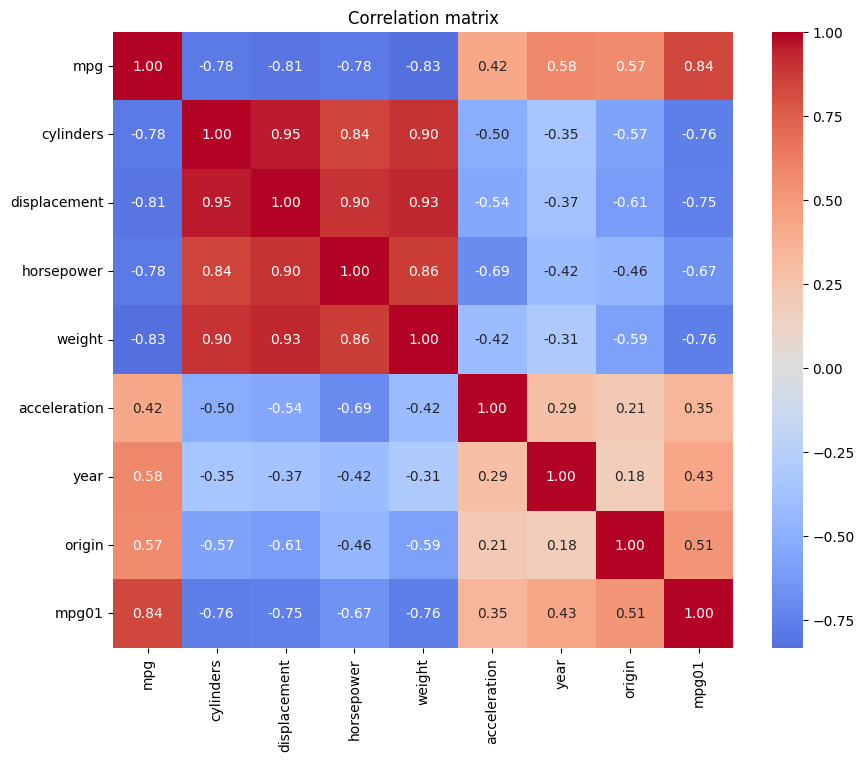

In [10]:
# Korrelacios hoterkep az Auto adathalmazhoz
plt.figure(figsize=(10, 8))
sns.heatmap(Auto.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()


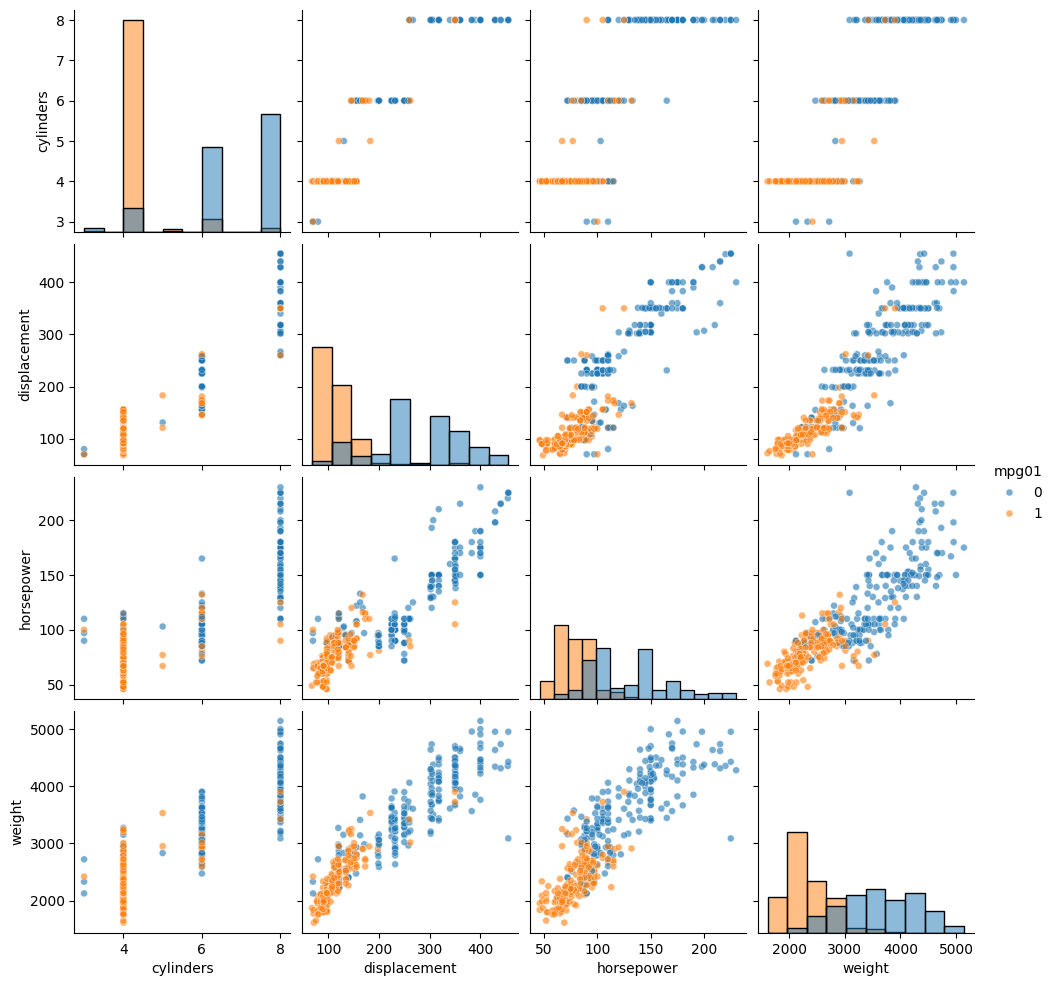

In [11]:
# A fontosabb valtozok pontdiagramjai mpg01 szerinti szinezessel
sns.pairplot(
    Auto,
    vars=["cylinders", "displacement", "horsepower", "weight"],
    hue="mpg01",
    diag_kind="hist",
    plot_kws={"alpha": 0.6, "s": 25}
)
plt.show()


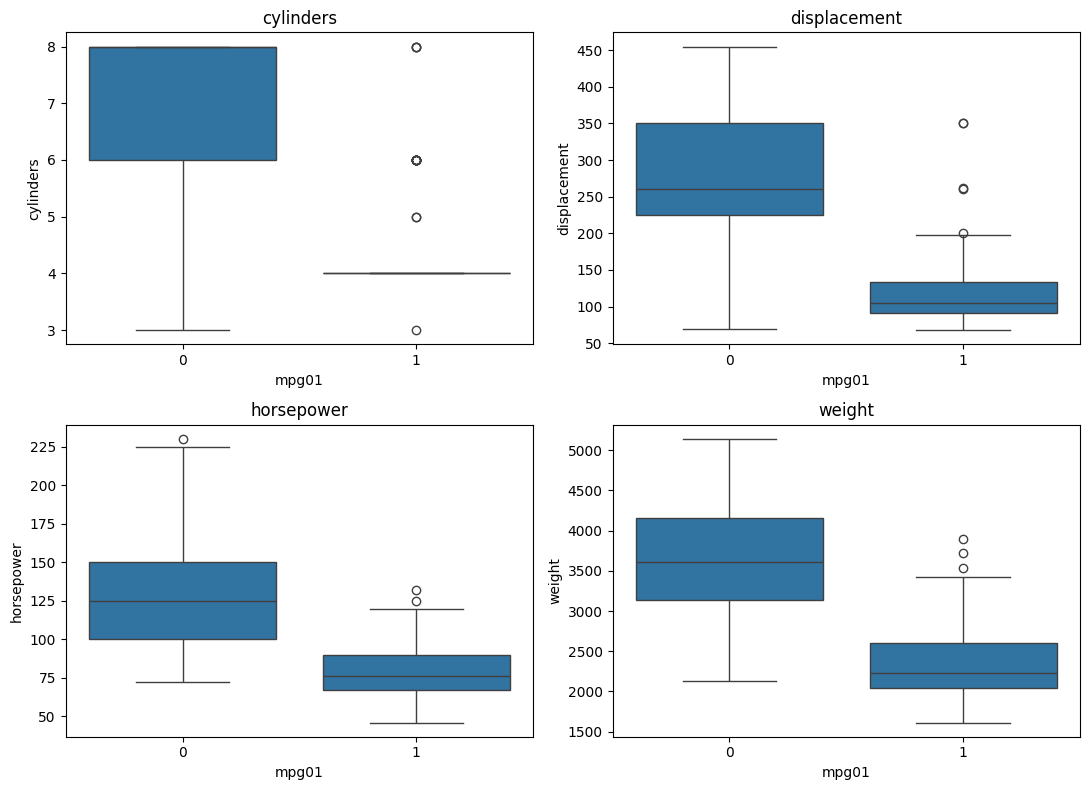

In [12]:
# Dobozdiagramok a kivalasztott valtozokhoz
selected_features = ["cylinders", "displacement", "horsepower", "weight"]
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

for feature, ax in zip(selected_features, axes.ravel()):
    sns.boxplot(data=Auto, x="mpg01", y=feature, ax=ax)
    ax.set_title(feature)

plt.tight_layout()
plt.show()


A grafikonok alapján a `cylinders`, `displacement`, `horsepower` és `weight` mutatja a legerősebb kapcsolatot az `mpg01` változóval. A magas `mpg` kategóriába tartozó autók jellemzően könnyebbek, kisebb motorral és kisebb teljesítménnyel rendelkeznek, valamint kevesebb hengerük van.

A négy változó egymással is erősen összefügg. A nagyobb motor általában több hengerrel, nagyobb teljesítménnyel és nagyobb tömeggel jár együtt. Ez azt jelenti, hogy részben ugyanazt a járműméretet és motorteljesítményt leíró információt hordozzák. Ettől függetlenül ezek a változók szemmel láthatóan jól elkülönítik a két fogyasztási kategóriát, ezért ezeket használjuk a modellekben.


## 14. c) Tanítási és teszthalmaz létrehozása

Az adatok 70%-át tanításra, 30%-át tesztelésre használjuk. A tanítási halmazon becsüljük a modellek paramétereit, a teszthalmaz pedig olyan adatokat tartalmaz, amelyeket a modellek az illesztés során nem láttak. Így reálisabban mérhető az általánosítási képesség.

A `random_state=1` biztosítja, hogy a felosztás minden futtatáskor ugyanaz legyen. Ez fontos a reprodukálhatóság miatt, és lehetővé teszi, hogy az egyes módszereket pontosan azonos tesztmegfigyeléseken hasonlítsuk össze.


In [13]:
# A bemeneti es celvaltozok kivalasztasa
X_auto = Auto[selected_features]
y_auto = Auto["mpg01"]

# Az adatok veletlen felosztasa
X_auto_train, X_auto_test, y_auto_train, y_auto_test = train_test_split(
    X_auto,
    y_auto,
    test_size=0.3,
    random_state=1
)

print("Training observations:", len(X_auto_train))
print("Test observations:", len(X_auto_test))


Training observations: 274
Test observations: 118


A modellek értékeléséhez a teszthibát használjuk. A teszthiba a hibásan osztályozott tesztmegfigyelések aránya.


In [14]:
# Segedfuggveny a modell eredmenyenek megjelenitesehez
def evaluate_auto_model(model_name, predictions):
    table = confusion_table_hu(predictions, y_auto_test, [0, 1])
    test_error = error_rate(y_auto_test, predictions)
    print(model_name)
    display(table)
    print("Test error:", test_error)
    return test_error


## 14. d) LDA

A lineáris diszkriminanciaanalízis, vagyis LDA azt feltételezi, hogy a bemeneti változók osztályonként többváltozós normális eloszlást követnek, és a két osztály kovarianciamátrixa azonos. Ezekből a feltételezésekből lineáris döntési határ adódik.

Az LDA előnye, hogy viszonylag kevés paramétert becsül, ezért kisebb adathalmazokon is stabil lehet. Hátránya, hogy ha az osztályok szóródási szerkezete jelentősen eltér, a közös kovarianciamátrix feltételezése túl szigorú lehet.


In [15]:
# LDA modell illesztese es ertekelese
lda_auto = LDA()
lda_auto.fit(X_auto_train, y_auto_train)
lda_auto_predictions = lda_auto.predict(X_auto_test)
lda_auto_error = evaluate_auto_model("LDA", lda_auto_predictions)


LDA


Truth,0,1
Predicted,,
0,58,3
1,7,50


Test error: 0.0847457627118644


Az LDA teszthibája körülbelül **8,5%**, vagyis a tesztmegfigyelések több mint 91%-át helyesen osztályozza. Ez arra utal, hogy a kiválasztott négy műszaki változó erős információt tartalmaz az üzemanyag-hatékonysági kategóriáról, és a lineáris döntési határ már önmagában is jól működik.


## 14. e) QDA

A kvadratikus diszkriminanciaanalízis, vagyis QDA az LDA-nál rugalmasabb. Nem feltételez közös kovarianciamátrixot, hanem minden osztályhoz külön kovarianciamátrixot becsül. Emiatt a döntési határ nem lineáris, hanem kvadratikus lehet.

A nagyobb rugalmasság előnyös lehet, ha a két osztály eloszlása eltérő alakú. Ugyanakkor a QDA több paramétert becsül, ezért kis mintán érzékenyebb lehet. Ebben az adathalmazban azonban a plusz rugalmasság enyhe javulást eredményez.


In [16]:
# QDA modell illesztese es ertekelese
qda_auto = QDA()
qda_auto.fit(X_auto_train, y_auto_train)
qda_auto_predictions = qda_auto.predict(X_auto_test)
qda_auto_error = evaluate_auto_model("QDA", qda_auto_predictions)


QDA


Truth,0,1
Predicted,,
0,61,5
1,4,48


Test error: 0.07627118644067797


A QDA teszthibája körülbelül **7,6%**, tehát kissé jobb eredményt ad az LDA-nál. Ez arra utal, hogy a két `mpg01` osztály változóinak szóródása nem teljesen azonos, és a kvadratikus döntési határ valamivel jobban követi a csoportok elhelyezkedését.

A különbség ugyanakkor csak egyetlen tesztmegfigyelés nagyságrendjébe esik, ezért nem jelent nagy előnyt.


## 14. f) Logisztikus regresszió

A logisztikus regresszió közvetlenül annak valószínűségét becsüli, hogy egy jármű a magas `mpg` kategóriába tartozik. A bemeneti változók lineáris kombinációját a logisztikus függvény alakítja 0 és 1 közötti valószínűséggé.

A módszer jól értelmezhető, mert az együtthatók megmutatják, hogy egy változó növekedése milyen irányban változtatja a magas `mpg` kategória esélyét. Az osztályozáshoz a becsült valószínűséget általában 0,5-ös küszöbbel alakítjuk kategóriává.


In [17]:
# Logisztikus regresszio illesztese es ertekelese
logistic_auto = LogisticRegression(max_iter=1000)
logistic_auto.fit(X_auto_train, y_auto_train)
logistic_auto_predictions = logistic_auto.predict(X_auto_test)
logistic_auto_error = evaluate_auto_model(
    "Logistic regression",
    logistic_auto_predictions
)


Logistic regression


Truth,0,1
Predicted,,
0,59,4
1,6,49


Test error: 0.0847457627118644


A logisztikus regresszió teszthibája körülbelül **8,5%**, így az LDA-val közel azonos teljesítményt nyújt. Ez nem meglepő, mert mindkét módszer alapvetően lineáris döntési határt eredményez, bár eltérő statisztikai feltételezésekből indul ki.


## 14. g) Naiv Bayes-osztályozás

A Gaussian Naive Bayes osztályonként normális eloszlást feltételez minden bemeneti változóra. Emellett feltételezi, hogy a változók az osztály ismeretében egymástól függetlenek. Ez a függetlenségi feltételezés ebben az adathalmazban biztosan nem teljesül tökéletesen, mert a hengerszám, lökettérfogat, teljesítmény és tömeg erősen összefügg egymással.

A módszer ennek ellenére gyakran jól működik, mert egyszerű, kevés paramétert becsül, és a kategóriák közötti erős különbségeket akkor is képes felismerni, ha a függetlenségi feltétel csak közelítőleg igaz.


In [18]:
# Naive Bayes modell illesztese es ertekelese
nb_auto = GaussianNB()
nb_auto.fit(X_auto_train, y_auto_train)
nb_auto_predictions = nb_auto.predict(X_auto_test)
nb_auto_error = evaluate_auto_model("Naive Bayes", nb_auto_predictions)


Naive Bayes


Truth,0,1
Predicted,,
0,60,5
1,5,48


Test error: 0.0847457627118644


A naiv Bayes-modell teszthibája körülbelül **8,5%**. A teljesítmény az LDA és a logisztikus regresszió eredményéhez hasonló. Ez azt mutatja, hogy a változók közötti függőség ellenére az osztályok közötti különbségek elég erősek a jó osztályozáshoz.


## 14. h) KNN több K értékkel

A KNN ebben a feladatban a járműveket a műszaki jellemzőik alapján hasonlítja össze. Egy tesztautó kategóriáját a hozzá legközelebb található tanítási autók többségi kategóriája határozza meg.

A négy bemeneti változó eltérő mértékegységű és számtartományú. A tömeg például több ezres értékeket is felvehet, míg a hengerszám csak néhány egész értékből áll. Standardizálás nélkül a tömeg szinte teljesen meghatározná a távolságokat. Ezért minden változót nulla átlagú és egységnyi szórású skálára alakítunk.

A skálázót csak a tanítási adatokon illesztjük. Ezután `K = 1` és `K = 199` között megkeressük a legkisebb teszthibát adó értéket. A K kiválasztása az illeszkedés és az általánosítás közötti egyensúlyt szabályozza: kis K rugalmas, de zajérzékeny, nagy K stabilabb, de túlságosan simíthat.


In [19]:
# A bemeneti valtozok standardizalasa
scaler_auto = StandardScaler()
X_auto_train_scaled = scaler_auto.fit_transform(X_auto_train)
X_auto_test_scaled = scaler_auto.transform(X_auto_test)

# A K ertekekhez tartozo teszthibak kiszamitasa
knn_auto_errors = {}

for k in range(1, 200):
    knn_auto = KNeighborsClassifier(n_neighbors=k)
    knn_auto.fit(X_auto_train_scaled, y_auto_train)
    knn_predictions = knn_auto.predict(X_auto_test_scaled)
    knn_auto_errors[k] = error_rate(y_auto_test, knn_predictions)

# A legjobb K ertek es a hozza tartozo teszthiba
best_k = min(knn_auto_errors, key=knn_auto_errors.get)
best_knn_error = knn_auto_errors[best_k]

print("Best K:", best_k)
print("Best test error:", best_knn_error)


Best K: 8
Best test error: 0.059322033898305086


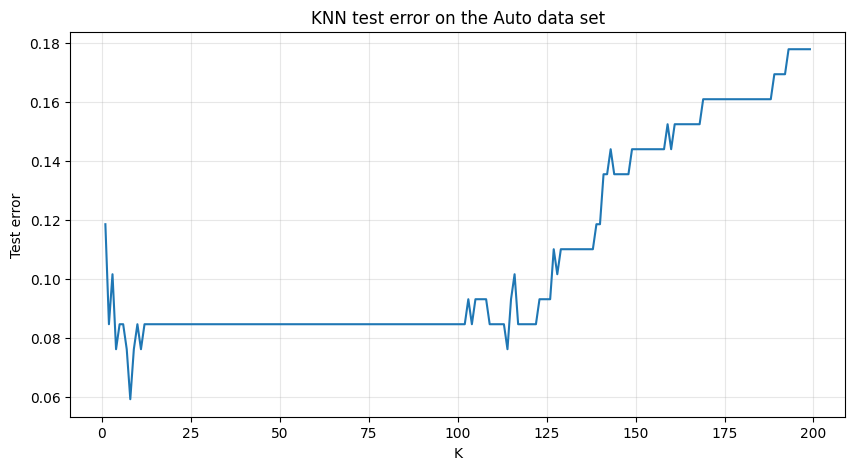

In [20]:
# A teszthiba abrazolasa K fuggvenyeben
plt.figure(figsize=(10, 5))
plt.plot(knn_auto_errors.keys(), knn_auto_errors.values())
plt.xlabel("K")
plt.ylabel("Test error")
plt.title("KNN test error on the Auto data set")
plt.grid(alpha=0.3)
plt.show()


A diagram alapján a teszthiba K = 8 esetén a legkisebb. A KNN-osztályozó minimális teszthibája 5,93%. Ez a vizsgált módszerek közül a legalacsonyabb teszthiba.

Az eredmény azt jelzi, hogy az osztályok döntési határa nem feltétlenül írható le tökéletesen egyetlen lineáris vagy kvadratikus felülettel. A KNN lokálisan, a közeli autók alapján dönt, ezért képes lehet jobban követni az adatok tényleges csoportosulását.



## Modellek összehasonlítása

Az egyes modellek ugyanazon tanítási és tesztfelosztáson készültek, ezért a teszthibáik közvetlenül összehasonlíthatók. A kisebb teszthiba jobb általánosítási teljesítményt jelent.

Az összehasonlításnál nemcsak a legkisebb számot érdemes figyelni. Az LDA és a logisztikus regresszió például egyszerűbb, könnyebben értelmezhető modellek, míg a KNN kevesebb szerkezeti feltételezést használ, de érzékeny a skálázásra és a K megválasztására.


In [21]:
# Az Auto modellek teszthibainak osszefoglalasa
auto_model_results = pd.DataFrame({
    "test_error": [
        lda_auto_error,
        qda_auto_error,
        logistic_auto_error,
        nb_auto_error,
        best_knn_error
    ]
}, index=[
    "LDA",
    "QDA",
    "Logistic regression",
    "Naive Bayes",
    "KNN"
])

auto_model_results.sort_values("test_error")


,test_error
KNN,0.059322
QDA,0.076271
Logistic regression,0.084746
LDA,0.084746
Naive Bayes,0.084746
